<a href="https://colab.research.google.com/github/inmira/Credit-Risk/blob/main/Credit_Card_Default_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Credit Card Default Prediction

**Machine Learning · Credit Risk · Imbalanced Classification · Model Explainability**

This project builds and compares machine learning models for predicting credit card payment default using the **UCI Default of Credit Card Clients** dataset.

The workflow covers data preparation, exploratory analysis, stratified cross-validation, class-imbalance handling, threshold optimization, model evaluation, and SHAP-based interpretation.

## Project snapshot

| Item | Details |
|---|---|
| Dataset | UCI Default of Credit Card Clients |
| Observations | 30,000 clients |
| Predictors | 23 |
| Target | `DEFAULT` — 1: default, 0: no default |
| Models | Logistic Regression, Random Forest, Random Forest + SMOTE, LightGBM |
| Validation | Stratified 5-fold cross-validation + stratified 80/20 hold-out test set |
| Best model in this run | **LightGBM** |
| Test ROC-AUC | **0.7780** |
| Test Average Precision | **0.5512** |

## Main result

LightGBM achieved the strongest overall ranking performance in this experiment, with a test ROC-AUC of **0.7780** and Average Precision of **0.5512**. At the threshold selected on out-of-fold training predictions, it achieved **0.5365 recall** and **0.5353 precision** for the default class.

SMOTE changed the precision–recall balance for Random Forest. At a fixed threshold of 0.50, default recall increased from **0.3640 to 0.4107**, while precision decreased from **0.6536 to 0.6151**. ROC-AUC changed only slightly (0.7641 to 0.7652).



## 1. Install and import libraries

Install the project dependencies in one step. The package list is also provided in `requirements.txt` for local reproduction.

In [1]:
%pip -q install ucimlrepo imbalanced-learn lightgbm shap

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    RocCurveDisplay, PrecisionRecallDisplay,
    precision_recall_curve
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5

pd.set_option("display.max_columns", 30)

## 2. Load the UCI dataset

The dataset contains 30,000 client records and 23 explanatory variables. The target indicates whether a client defaulted on payment in the following month.

In [3]:
uci_data = fetch_ucirepo(id=350)

X_raw = uci_data.data.features.copy()
y_raw = uci_data.data.targets.squeeze().copy()

print("Feature shape:", X_raw.shape)
print("Target name:", y_raw.name)
print("Target values:", sorted(pd.Series(y_raw).dropna().unique().tolist()))
display(X_raw.head())

Feature shape: (30000, 23)
Target name: Y
Target values: [0, 1]


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679


## 3. Prepare and name the features

The UCI file often labels the columns as `X1`–`X23`. The mapping below uses the variable definitions from the dataset documentation.

- `LIMIT_BAL`: credit limit
- `PAY_0`–`PAY_6`: repayment status
- `BILL_AMT1`–`BILL_AMT6`: statement bill amounts
- `PAY_AMT1`–`PAY_AMT6`: previous payment amounts

The target is normalized to 0/1. No target-derived information is used as a feature.

In [4]:
feature_names = [
    "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE",
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]

if X_raw.shape[1] != len(feature_names):
    raise ValueError(f"Expected 23 features, received {X_raw.shape[1]}.")

X = X_raw.copy()
X.columns = feature_names

# UCI target is usually named Y and coded 1 = default, 0 = no default.
y = pd.to_numeric(y_raw, errors="raise").astype(int)
y.name = "DEFAULT"

if set(y.unique()) != {0, 1}:
    raise ValueError(f"Expected binary target values 0 and 1, got {sorted(y.unique())}.")

# Ensure numeric features and make missing values explicit for pipeline imputation.
X = X.apply(pd.to_numeric, errors="coerce")

df = X.copy()
df["DEFAULT"] = y

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
display(y.value_counts().rename(index={0: "No default (0)", 1: "Default (1)"}).to_frame("count"))
display((y.value_counts(normalize=True) * 100).rename(index={0: "No default (0)", 1: "Default (1)"}).round(2).to_frame("percent"))

print("\nMissing values by column:")
display(X.isna().sum().sort_values(ascending=False).head(10).to_frame("missing"))

Dataset shape: (30000, 24)

Target distribution:


,count
DEFAULT,
No default (0),23364
Default (1),6636


,percent
DEFAULT,
No default (0),77.88
Default (1),22.12



Missing values by column:


,missing
LIMIT_BAL,0
SEX,0
EDUCATION,0
MARRIAGE,0
AGE,0
PAY_0,0
PAY_2,0
PAY_3,0
PAY_4,0
PAY_5,0


## 4. Exploratory data analysis

The target is imbalanced: defaults represent **22.12%** of observations. Accuracy alone can therefore be misleading. The evaluation uses ROC-AUC, Average Precision, precision, recall, and F1 for the default class.

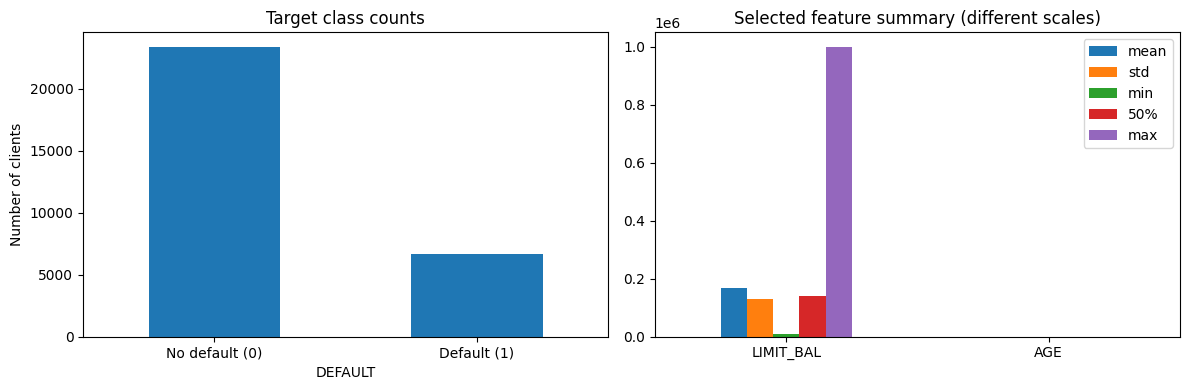

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

y.value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_xticks([0, 1], ["No default (0)", "Default (1)"], rotation=0)
axes[0].set_title("Target class counts")
axes[0].set_ylabel("Number of clients")

(X[["LIMIT_BAL", "AGE"]] .describe().T)[["mean", "std", "min", "50%", "max"]].plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Selected feature summary (different scales)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## 5. Train–test split

The test set is held out before cross-validation. All model selection and threshold selection happen using only the training data.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("\nDefault rate — train:", round(y_train.mean(), 4))
print("Default rate — test: ", round(y_test.mean(), 4))

Training rows: 24000
Test rows: 6000

Default rate — train: 0.2212
Default rate — test:  0.2212


## 6. Define models and cross-validation

All models use median imputation inside the pipeline. Logistic Regression also uses `StandardScaler`, because its optimization is sensitive to feature scale.

For the SMOTE model, the oversampler is inside the imbalanced-learn pipeline. During each CV fold, SMOTE sees only that fold's training partition. The validation fold and final test set retain their original class distribution.

We use LightGBM as an additional tree-based benchmark. The model settings are intentionally moderate rather than exhaustively tuned.

In [7]:
models = {
    "Logistic Regression": SklearnPipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, class_weight=None, random_state=RANDOM_STATE))
    ]),
    "Random Forest": SklearnPipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=RANDOM_STATE,
            class_weight=None
        ))
    ]),
    "Random Forest + SMOTE": ImbPipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=RANDOM_STATE,
            class_weight=None
        ))
    ]),
    "LightGBM": SklearnPipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LGBMClassifier(
            n_estimators=500,
            learning_rate=0.03,
            num_leaves=20,
            max_depth=-1,
            min_child_samples=30,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=1.0,
            class_weight=None,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        ))
    ])
}

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

## 7. Out-of-fold predictions and CV comparison

`cross_val_predict` produces one out-of-fold probability for every training observation. Each prediction comes from a model that did not train on that observation.

We use these probabilities to:
1. calculate an out-of-fold ROC-AUC and average precision;
2. select a candidate threshold using the training data only.

The default threshold of 0.50 is included as a reference. The F1-optimal threshold is only one possible choice; in a real credit-risk setting, the threshold should reflect the business costs of false positives and false negatives.

In [8]:
oof_probabilities = {}
cv_rows = []

for model_name, model in models.items():
    print(f"Cross-validating: {model_name}")
    oof_prob = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=None
    )[:, 1]

    oof_probabilities[model_name] = oof_prob
    cv_rows.append({
        "Model": model_name,
        "OOF ROC-AUC": roc_auc_score(y_train, oof_prob),
        "OOF Average Precision": average_precision_score(y_train, oof_prob)
    })

cv_results = pd.DataFrame(cv_rows).sort_values("OOF ROC-AUC", ascending=False).reset_index(drop=True)
display(cv_results.round(4))

Cross-validating: Logistic Regression
Cross-validating: Random Forest
Cross-validating: Random Forest + SMOTE
Cross-validating: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,OOF ROC-AUC,OOF Average Precision
0,LightGBM,0.7816,0.5574
1,Random Forest,0.7742,0.5502
2,Random Forest + SMOTE,0.7733,0.5431
3,Logistic Regression,0.7259,0.5042


## 8. Choose thresholds using training data only

For each model, the threshold is selected by maximizing F1 on its out-of-fold training predictions. This is a transparent baseline, not a universal business optimum.

A different threshold can be selected if the business specifies:
- a minimum acceptable recall for defaults;
- a maximum acceptable share of clients incorrectly flagged;
- explicit costs for false negatives and false positives.

In [9]:
thresholds = {}

for model_name, prob in oof_probabilities.items():
    precision, recall, threshold_values = precision_recall_curve(y_train, prob)

    # precision_recall_curve returns one more precision/recall point than thresholds.
    f1_values = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    best_idx = int(np.nanargmax(f1_values))
    thresholds[model_name] = float(threshold_values[best_idx])

threshold_table = pd.DataFrame({
    "Model": list(thresholds.keys()),
    "F1-selected threshold": list(thresholds.values())
})
display(threshold_table.round(4))

,Model,F1-selected threshold
0,Logistic Regression,0.2864
1,Random Forest,0.3448
2,Random Forest + SMOTE,0.3788
3,LightGBM,0.3084


## 9. Fit on the full training set and evaluate on the untouched test set

The test metrics below use each model's training-selected threshold. We also show the default 0.50 threshold for the Random Forest models so that the effect of changing the threshold can be separated from the effect of SMOTE.

ROC-AUC is calculated from probabilities and is unchanged by threshold selection.

In [10]:
fitted_models = {}
test_probabilities = {}
test_rows = []

for model_name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[model_name] = model

    prob = model.predict_proba(X_test)[:, 1]
    test_probabilities[model_name] = prob

    threshold = thresholds[model_name]
    pred = (prob >= threshold).astype(int)

    test_rows.append({
        "Model": model_name,
        "Threshold": threshold,
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Average Precision": average_precision_score(y_test, prob),
        "Precision (default)": precision_score(y_test, pred, zero_division=0),
        "Recall (default)": recall_score(y_test, pred, zero_division=0),
        "F1 (default)": f1_score(y_test, pred, zero_division=0)
    })

test_results = pd.DataFrame(test_rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(test_results.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Threshold,ROC-AUC,Average Precision,Precision (default),Recall (default),F1 (default)
0,LightGBM,0.3084,0.7780,0.5512,0.5353,0.5365,0.5359
1,Random Forest + SMOTE,0.3788,0.7652,0.5433,0.5279,0.5275,0.5277
2,Random Forest,0.3448,0.7641,0.5461,0.5498,0.5079,0.5280
3,Logistic Regression,0.2864,0.7076,0.4939,0.5319,0.4770,0.5030


In [11]:
# Direct comparison: Random Forest and Random Forest + SMOTE at threshold 0.50
rf_threshold_rows = []

for model_name in ["Random Forest", "Random Forest + SMOTE"]:
    prob = test_probabilities[model_name]
    pred_05 = (prob >= 0.50).astype(int)
    rf_threshold_rows.append({
        "Model": model_name,
        "Threshold": 0.50,
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Precision (default)": precision_score(y_test, pred_05, zero_division=0),
        "Recall (default)": recall_score(y_test, pred_05, zero_division=0),
        "F1 (default)": f1_score(y_test, pred_05, zero_division=0)
    })

display(pd.DataFrame(rf_threshold_rows).round(4))

,Model,Threshold,ROC-AUC,Precision (default),Recall (default),F1 (default)
0,Random Forest,0.5,0.7641,0.6536,0.3640,0.4676
1,Random Forest + SMOTE,0.5,0.7652,0.6151,0.4107,0.4925


## 10. Precision–recall and ROC curves

The precision–recall curve is particularly informative when the positive class is relatively rare. Moving the threshold usually increases recall at the expense of precision, or vice versa.

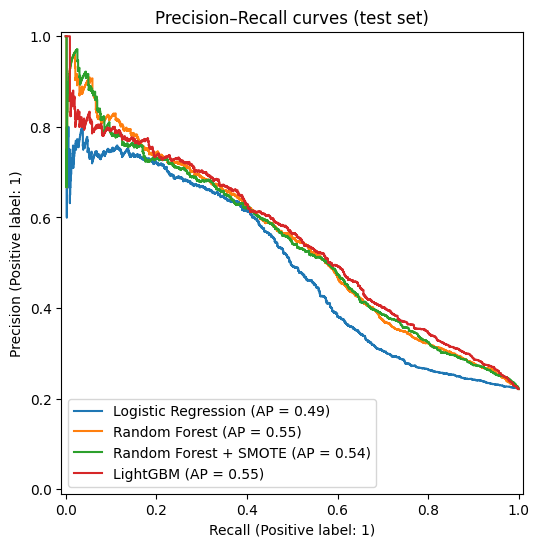

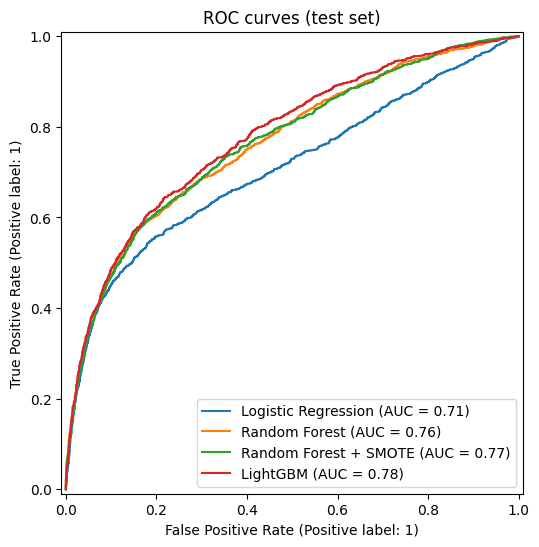

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
for model_name, prob in test_probabilities.items():
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=model_name, ax=ax)
ax.set_title("Precision–Recall curves (test set)")
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for model_name, prob in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=model_name, ax=ax)
ax.set_title("ROC curves (test set)")
plt.show()

## 11. Confusion matrix and classification report

The following report uses the training-selected threshold for the model with the highest cross-validation ROC-AUC. The model is selected by CV performance, not by its test-set score.

In [13]:
best_model_name = cv_results.loc[0, "Model"]
best_model = fitted_models[best_model_name]
best_threshold = thresholds[best_model_name]
best_test_prob = test_probabilities[best_model_name]
best_test_pred = (best_test_prob >= best_threshold).astype(int)

print("Selected model:", best_model_name)
print("Threshold selected on OOF training predictions:", round(best_threshold, 4))
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, best_test_pred))
print("\nClassification report:")
print(classification_report(
    y_test, best_test_pred,
    target_names=["No default (0)", "Default (1)"],
    zero_division=0
))

Selected model: LightGBM
Threshold selected on OOF training predictions: 0.3084

Confusion matrix (rows = actual, columns = predicted):
[[4055  618]
 [ 615  712]]

Classification report:
                precision    recall  f1-score   support

No default (0)       0.87      0.87      0.87      4673
   Default (1)       0.54      0.54      0.54      1327

      accuracy                           0.79      6000
     macro avg       0.70      0.70      0.70      6000
  weighted avg       0.79      0.79      0.79      6000



## 12. Feature importance

For tree models, impurity-based feature importance provides a quick overview. It can be biased toward features with many possible split points and should not be interpreted as causal impact.

We display importance for the best-performing tree model among Random Forest, Random Forest + SMOTE and LightGBM, selected by out-of-fold ROC-AUC.

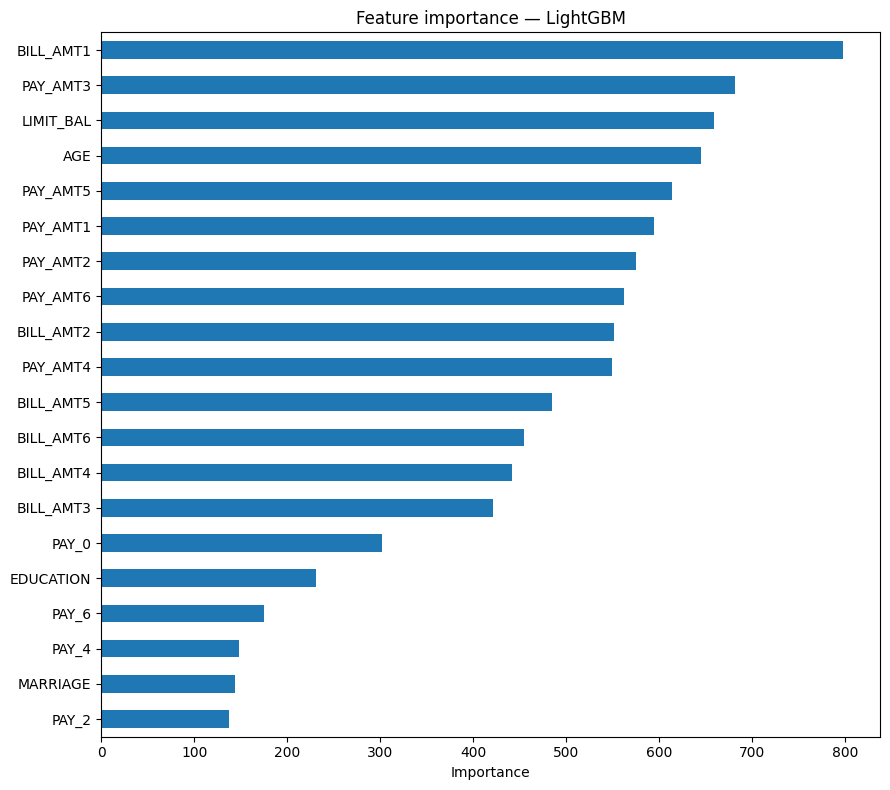

Tree model used: LightGBM


,importance
BILL_AMT1,798
PAY_AMT3,682
LIMIT_BAL,659
AGE,645
PAY_AMT5,614
PAY_AMT1,595
PAY_AMT2,575
PAY_AMT6,563
BILL_AMT2,552
PAY_AMT4,550


In [14]:
tree_candidates = [
    name for name in ["Random Forest", "Random Forest + SMOTE", "LightGBM"]
    if name in fitted_models
]
best_tree_name = max(
    tree_candidates,
    key=lambda name: cv_results.loc[cv_results["Model"] == name, "OOF ROC-AUC"].iloc[0]
)
best_tree_pipeline = fitted_models[best_tree_name]
tree_model = best_tree_pipeline.named_steps["model"]

importances = pd.Series(
    tree_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

plt.figure(figsize=(9, 8))
importances.tail(20).plot(kind="barh")
plt.title(f"Feature importance — {best_tree_name}")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print("Tree model used:", best_tree_name)
display(importances.sort_values(ascending=False).head(15).to_frame("importance"))

## 13. SHAP explanation with TreeExplainer

`shap.TreeExplainer` is designed for tree-based models and is substantially more efficient than a generic explainer for Random Forest and LightGBM.

We explain a sample of test observations. The feature names are retained so that the summary plot is interpretable. SHAP values describe how features contribute to this model's predictions; they do not establish causal effects.

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


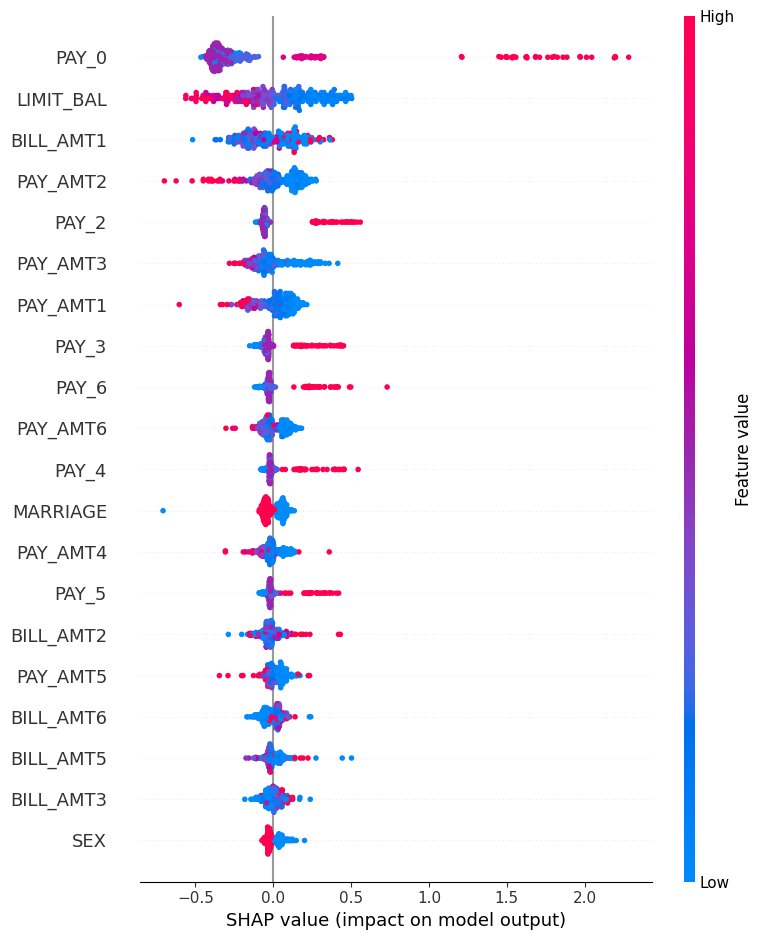

In [15]:
# A modest sample keeps explanation time and memory use manageable.
X_explain = X_test.sample(n=min(300, len(X_test)), random_state=RANDOM_STATE)
X_explain_imp = pd.DataFrame(
    best_tree_pipeline.named_steps["imputer"].transform(X_explain),
    columns=X_explain.columns,
    index=X_explain.index
)

explainer = shap.TreeExplainer(tree_model)
shap_values = explainer.shap_values(X_explain_imp)

# SHAP output format differs across SHAP/model versions.
if isinstance(shap_values, list):
    values_for_default = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    values_for_default = shap_values[:, :, 1]
else:
    values_for_default = shap_values

shap.summary_plot(
    values_for_default,
    X_explain_imp,
    feature_names=X_explain_imp.columns,
    show=True
)

## 14. Interpretation and conclusions

### Model comparison

**LightGBM achieved the best overall performance in this experiment.**

- OOF ROC-AUC: **0.7816**
- Test ROC-AUC: **0.7780**
- Test Average Precision: **0.5512**
- Test precision for defaults: **0.5353**
- Test recall for defaults: **0.5365**
- Test F1 for defaults: **0.5359**
- F1-selected threshold: **0.3084**

The close OOF and test ROC-AUC values suggest that LightGBM's ranking performance was consistent across the training cross-validation and held-out test evaluation in this split.

### What did SMOTE change?

At a fixed classification threshold of 0.50, Random Forest with SMOTE produced:

| Metric | Random Forest | Random Forest + SMOTE |
|---|---:|---:|
| ROC-AUC | 0.7641 | 0.7652 |
| Precision (default) | **0.6536** | 0.6151 |
| Recall (default) | 0.3640 | **0.4107** |
| F1 (default) | 0.4676 | **0.4925** |

SMOTE increased default recall from **0.3640 to 0.4107**, while precision decreased from **0.6536 to 0.6151**. ROC-AUC changed only slightly. This indicates a shift in the precision–recall balance rather than a broad improvement across all metrics.

Threshold selection also matters: the F1-selected thresholds were below 0.50 for all four models. A lower threshold can increase the number of predicted defaults without changing the underlying probability-ranking model.

### Features contributing to the LightGBM model

The highest-ranked features by LightGBM split importance included:

1. `BILL_AMT1`
2. `PAY_AMT3`
3. `LIMIT_BAL`
4. `AGE`
5. `PAY_AMT5`
6. `PAY_AMT1`
7. `PAY_AMT2`
8. `PAY_AMT6`
9. `BILL_AMT2`
10. `PAY_AMT4`

The SHAP summary plot provides a complementary view of how feature values contribute to model predictions for the sampled test observations. These explanations describe model behavior and should not be interpreted as causal effects.

### Key takeaways

- LightGBM achieved the highest test ROC-AUC and Average Precision among the evaluated models.
- Stratified cross-validation and out-of-fold predictions were used for model comparison and threshold selection.
- SMOTE increased recall for the default class at a fixed threshold, with a reduction in precision.
- Threshold optimization changed the precision–recall trade-off and should be considered alongside model selection.
- Repayment and bill-related variables were prominent in the LightGBM feature-importance ranking.

### Evaluation notes

- Final test metrics are based on one stratified 80/20 hold-out split.
- The F1-based threshold was selected using out-of-fold training predictions, not the test set.
- The best threshold depends on the relative business costs of false negatives and false positives. F1 is used here as a general-purpose selection criterion.
- Feature importance and SHAP values describe model associations, not causal relationships.

---

